In [7]:

import os

print("Starting dataset search...")

print(os.listdir("/kaggle/input"))


Starting dataset search...
['competitions', 'notebooks']


In [ ]:

import os

print(os.listdir("/kaggle/input/competitions"))


In [ ]:

from pathlib import Path

data = Path(
    "/kaggle/input/competitions/"
    "imagenet-object-localization-challenge/"
    "ILSVRC/Data"
)

print("Data folder exists:", data.exists())

if data.exists():
    print("Inside Data:")
    for folder in data.iterdir():
        print(folder.name)

    cls = data / "CLS-LOC"

    if cls.exists():
        print("Inside CLS-LOC:")
        for folder in cls.iterdir():
            print(folder.name)


In [ ]:

from pathlib import Path

train_path = Path(
    "/kaggle/input/competitions/"
    "imagenet-object-localization-challenge/"
    "ILSVRC/Data/CLS-LOC/train"
)

classes = {
    "n01692333": "Gila monster",
    "n02112350": "Keeshond",
    "n02112706": "Brabancon griffon",
    "n02422106": "Hartebeest",
    "n02640242": "Sturgeon",
    "n03743016": "Megalith",
    "n04270147": "Spatula",
    "n04458633": "Totem pole",
    "n04483307": "Trimaran",
    "n07753113": "Fig"
}

total = 0

for class_id, class_name in classes.items():
    folder = train_path / class_id

    if folder.exists():
        count = sum(
            1 for f in folder.iterdir() if f.is_file()
        )
        total += count
        print(class_name, ":", count, "images")
    else:
        print(class_name, ": NOT FOUND")

print("Total training-source images:", total)


In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

# 1. Locate our Gila monster images
folder = Path(
    "/kaggle/input/competitions/"
    "imagenet-object-localization-challenge/"
    "ILSVRC/Data/CLS-LOC/train/n01692333"
)

# 2. Select one image
images = sorted(
    f for f in folder.iterdir()
    if f.suffix.lower() in [".jpeg", ".jpg", ".png"]
)

image_path = images[0]

# 3. Open the original image
with Image.open(image_path) as img:
    original = img.copy()

# 4. Convert to RGB
rgb_image = original.convert("RGB")

# 5. Center-crop and resize to 64x64
processed = ImageOps.fit(
    rgb_image,
    (64, 64),
    method=Image.Resampling.LANCZOS
)

# 6. Print image information
print("Original size:", original.size)
print("Original mode:", original.mode)
print("Processed size:", processed.size)
print("Processed mode:", processed.mode)

# 7. Display both images
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(processed)
axes[1].set_title("RGB 64x64")

for ax in axes:
    ax.axis("off")

plt.show()


In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
from collections import Counter
import numpy as np
import pandas as pd

# 1. Paths
train_path = Path(
    "/kaggle/input/competitions/"
    "imagenet-object-localization-challenge/"
    "ILSVRC/Data/CLS-LOC/train"
)

output = Path("/kaggle/working/t23_dataset")
output.mkdir(parents=True, exist_ok=True)

# 2. Our ten classes, in their required label order
classes = {
    "n01692333": 0,
    "n02112350": 1,
    "n02112706": 2,
    "n02422106": 3,
    "n02640242": 4,
    "n03743016": 5,
    "n04270147": 6,
    "n04458633": 7,
    "n04483307": 8,
    "n07753113": 9
}

# 3. Lists to hold the processed data
images = []
labels = []
records = []
rejected = []
original_modes = Counter()

# 4. Process every image
for class_id, label in classes.items():

    folder = train_path / class_id
    files = sorted(
        f for f in folder.iterdir()
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )

    for file in files:
        try:
            with Image.open(file) as img:

                mode = img.mode
                original_size = img.size

                # Correct orientation, convert to RGB
                rgb = ImageOps.exif_transpose(img).convert("RGB")

                # Center crop and resize
                processed = ImageOps.fit(
                    rgb,
                    (64, 64),
                    method=Image.Resampling.LANCZOS
                )

                array = np.array(processed, dtype=np.uint8)

            images.append(array)
            labels.append(label)
            original_modes[mode] += 1

            records.append({
                "filename": file.name,
                "class_id": class_id,
                "label": label,
                "original_mode": mode,
                "original_width": original_size[0],
                "original_height": original_size[1]
            })

        except Exception as e:
            rejected.append({
                "filename": str(file),
                "reason": str(e)
            })

    print("Completed class", label, class_id)

# 5. Convert lists into NumPy arrays
X = np.stack(images)
y = np.array(labels, dtype=np.uint8)

# 6. Save the dataset and processing records
np.save(output / "train_source_images.npy", X)
np.save(output / "train_source_labels.npy", y)

pd.DataFrame(records).to_csv(
    output / "train_source_manifest.csv",
    index=False
)

pd.DataFrame(rejected, columns=["filename", "reason"]).to_csv(
    output / "rejected_images.csv",
    index=False
)

# 7. Print the final results
print("\nDataset preparation completed!")
print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Original colour modes:", dict(original_modes))
print("Rejected images:", len(rejected))
print("Saved to:", output)


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

# 1. Locate our saved dataset
output = Path("/kaggle/working/t23_dataset")

# 2. Load the labels of all 12,770 images
y = np.load(output / "train_source_labels.npy")

# 3. Use a fixed random seed
rng = np.random.default_rng(2026)

train_indices = []
val_indices = []
summary = []

# 4. Split each class separately
for label in range(10):

    # Find the positions of images in this class
    indices = np.where(y == label)[0]

    # Randomly shuffle those positions
    shuffled = rng.permutation(indices)

    # Take 10% for validation
    n_val = round(len(indices) * 0.10)

    val_indices.extend(shuffled[:n_val])
    train_indices.extend(shuffled[n_val:])

    summary.append({
        "Label": label,
        "Original": len(indices),
        "TRAIN": len(indices) - n_val,
        "VAL": n_val
    })

# 5. Convert to arrays
train_indices = np.array(sorted(train_indices))
val_indices = np.array(sorted(val_indices))

# 6. Check there is no overlap
assert len(np.intersect1d(
    train_indices, val_indices
)) == 0

assert len(train_indices) + len(val_indices) == len(y)

# 7. Save split index files
np.save(output / "train_indices.npy", train_indices)
np.save(output / "val_indices.npy", val_indices)

# 8. Save statistics for our report
summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    output / "split_summary.csv",
    index=False
)

print(summary_df.to_string(index=False))
print("Total TRAIN:", len(train_indices))
print("Total VAL:", len(val_indices))
print("No overlap: VERIFIED")


In [ ]:

import pandas as pd
from pathlib import Path

# Location of the Kaggle competition dataset
root = Path(
    "/kaggle/input/competitions/"
    "imagenet-object-localization-challenge"
)

# Official validation labels
csv_path = root / "LOC_val_solution.csv"

# Official validation images
val_folder = root / "ILSVRC/Data/CLS-LOC/val"

# Read the CSV file
df = pd.read_csv(csv_path)

# Extract the class ID from each label string
df["class_id"] = df["PredictionString"].str.split().str[0]

# Our Team T23 classes
classes = {
    "n01692333": 0,
    "n02112350": 1,
    "n02112706": 2,
    "n02422106": 3,
    "n02640242": 4,
    "n03743016": 5,
    "n04270147": 6,
    "n04458633": 7,
    "n04483307": 8,
    "n07753113": 9
}

# Select only our 10 classes
t23_test = df[df["class_id"].isin(classes)].copy()

# Print results
print("VAL folder exists:", val_folder.exists())
print("Images per T23 class:")
print(t23_test["class_id"].value_counts().sort_index())
print("Total selected images:", len(t23_test))

print("\nFirst five records:")
print(t23_test[["ImageId", "class_id"]].head())


In [ ]:

from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import pandas as pd

# 1. Locate the ImageNet validation data
root = Path(
    "/kaggle/input/competitions/"
    "imagenet-object-localization-challenge"
)

val_folder = root / "ILSVRC/Data/CLS-LOC/val"
output = Path("/kaggle/working/t23_dataset")
output.mkdir(parents=True, exist_ok=True)

# 2. Our official class labels
classes = {
    "n01692333": 0,
    "n02112350": 1,
    "n02112706": 2,
    "n02422106": 3,
    "n02640242": 4,
    "n03743016": 5,
    "n04270147": 6,
    "n04458633": 7,
    "n04483307": 8,
    "n07753113": 9
}

# 3. Read the official validation labels
df = pd.read_csv(root / "LOC_val_solution.csv")

df["class_id"] = (
    df["PredictionString"].str.split().str[0]
)

t23_test = df[
    df["class_id"].isin(classes)
].sort_values("ImageId")

# 4. Check our 500 official labels
assert len(t23_test) == 500
assert (t23_test["class_id"].value_counts() == 50).all()

# 5. Prepare arrays and processing records
test_images = []
test_labels = []
test_records = []
errors = []

# 6. Process every selected TEST image
for _, row in t23_test.iterrows():

    image_id = row["ImageId"]
    class_id = row["class_id"]
    label = classes[class_id]

    image_path = val_folder / (image_id + ".JPEG")

    try:
        with Image.open(image_path) as img:
            original_mode = img.mode
            original_size = img.size

            rgb = ImageOps.exif_transpose(img).convert("RGB")

            processed = ImageOps.fit(
                rgb,
                (64, 64),
                method=Image.Resampling.LANCZOS
            )

            array = np.array(processed, dtype=np.uint8)

        test_images.append(array)
        test_labels.append(label)

        test_records.append({
            "ImageId": image_id,
            "WordNet_ID": class_id,
            "Label": label,
            "Original_mode": original_mode,
            "Original_width": original_size[0],
            "Original_height": original_size[1]
        })

    except Exception as e:
        errors.append((image_id, str(e)))

# 7. Check all images were processed
if errors:
    print("Processing errors:", errors[:10])
    raise RuntimeError("Some TEST images failed processing")

# 8. Convert to NumPy arrays
X_test = np.stack(test_images)
y_test = np.array(test_labels, dtype=np.uint8)

# 9. Save images, labels and manifest
np.save(output / "test_images.npy", X_test)
np.save(output / "test_labels.npy", y_test)

pd.DataFrame(test_records).to_csv(
    output / "test_manifest.csv",
    index=False
)

# 10. Verify results
print("TEST preparation completed!")
print("TEST images shape:", X_test.shape)
print("TEST labels shape:", y_test.shape)
print("Images per class:", np.bincount(y_test))
print("Processing errors:", len(errors))


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

# 1. Location of our processed data
output = Path("/kaggle/working/t23_dataset")

# 2. Load the existing image arrays
X_source = np.load(
    output / "train_source_images.npy"
)
y_source = np.load(
    output / "train_source_labels.npy"
)

X_test = np.load(output / "test_images.npy")
y_test = np.load(output / "test_labels.npy")

# 3. Load our saved TRAIN and VAL indices
train_indices = np.load(output / "train_indices.npy")
val_indices = np.load(output / "val_indices.npy")

# 4. Combine the image arrays
X_all = np.concatenate(
    [X_source, X_test], axis=0
)

y_all = np.concatenate(
    [y_source, y_test], axis=0
)

# 5. Create TEST indices
# TEST images begin after the 12,770 source images
test_indices = np.arange(
    len(X_source), len(X_all)
)

# 6. Verify the three splits
assert X_all.shape == (13270, 64, 64, 3)
assert len(y_all) == 13270

assert len(train_indices) == 11493
assert len(val_indices) == 1277
assert len(test_indices) == 500

assert len(np.unique(np.concatenate([
    train_indices, val_indices, test_indices
]))) == len(X_all)

# 7. Save the final dataset
np.save(output / "images.npy", X_all)
np.save(output / "labels.npy", y_all)
np.save(output / "test_indices.npy", test_indices)

# 8. Save the final statistics table
summary = []

for label in range(10):
    summary.append({
        "Label": label,
        "TRAIN": int(np.sum(y_all[train_indices] == label)),
        "VAL": int(np.sum(y_all[val_indices] == label)),
        "TEST": int(np.sum(y_all[test_indices] == label))
    })

summary_df = pd.DataFrame(summary)
summary_df["Total"] = (
    summary_df["TRAIN"]
    + summary_df["VAL"]
    + summary_df["TEST"]
)

summary_df.to_csv(
    output / "final_dataset_summary.csv",
    index=False
)

print(summary_df.to_string(index=False))
print("\nFinal images shape:", X_all.shape)
print("Final labels shape:", y_all.shape)
print("Dataset size (MB):", round(X_all.nbytes / 1e6, 2))
print("All splits verified!")


In [ ]:

from pathlib import Path

folder = Path("/kaggle/working/t23_dataset")

print("Folder exists:", folder.exists())

if folder.exists():
    print("\nSaved files:")
    for file in sorted(folder.iterdir()):
        size = file.stat().st_size / (1024 * 1024)
        print(f"{file.name} : {size:.2f} MB")
else:
    print("Dataset folder not found!")


In [ ]:

import numpy as np
from pathlib import Path

folder = Path("/kaggle/working/t23_dataset")

X = np.load(folder / "images.npy")
y = np.load(folder / "labels.npy")

train_idx = np.load(folder / "train_indices.npy")
val_idx = np.load(folder / "val_indices.npy")
test_idx = np.load(folder / "test_indices.npy")

print("Images:", X.shape)
print("Labels:", y.shape)
print("Image dtype:", X.dtype)
print("Class labels:", np.unique(y))

for name, idx in [
    ("TRAIN", train_idx),
    ("VAL", val_idx),
    ("TEST", test_idx)
]:
    print(name, np.bincount(y[idx], minlength=10))
    
assert len(X) == len(y)
assert X.shape[1:] == (64, 64, 3)
assert X.dtype == np.uint8
assert np.array_equal(np.unique(y), np.arange(10))

print("NumPy format and label checks passed!")


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/kaggle/working/t23_dataset")

X = np.load(folder / "images.npy")
y = np.load(folder / "labels.npy")
train_idx = np.load(folder / "train_indices.npy")

class_names = [
    "Gila monster",
    "Keeshond",
    "Brabancon griffon",
    "Hartebeest",
    "Sturgeon",
    "Megalith",
    "Spatula",
    "Totem pole",
    "Trimaran",
    "Fig"
]

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for label in range(10):
    indices = train_idx[y[train_idx] == label]

    image = X[indices[0]]

    ax = axes.flat[label]
    ax.imshow(image)
    ax.set_title(f"{label}: {class_names[label]}")
    ax.axis("off")

plt.suptitle("Team T23 - ImageNet RGB 64x64 Samples")
plt.tight_layout()

plt.savefig(
    folder / "t23_class_samples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Classes we want to inspect
check_classes = [6, 7]

rng = np.random.default_rng(2026)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for row, label in enumerate(check_classes):

    indices = train_idx[y[train_idx] == label]

    selected = rng.choice(
        indices, size=5, replace=False
    )

    for col, idx in enumerate(selected):
        axes[row, col].imshow(X[idx])
        axes[row, col].set_title(
            f"Class {label} | Index {idx}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import torch
import numpy as np
from pathlib import Path

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Device: CPU")

folder = Path("/kaggle/working/t23_dataset")

print("\nDataset folder exists:", folder.exists())

if folder.exists():
    X = np.load(folder / "images.npy", mmap_mode="r")
    y = np.load(folder / "labels.npy")

    print("Images shape:", X.shape)
    print("Labels shape:", y.shape)
    print("Data type:", X.dtype)


In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Number of GPUs:", torch.cuda.device_count())
else:
    print("Running on CPU")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Number of GPUs: 2


In [2]:

from pathlib import Path
import numpy as np
import torch

folder = Path("/kaggle/working/t23_dataset")

print("Dataset exists:", folder.exists())

if folder.exists():
    X = np.load(folder / "images.npy", mmap_mode="r")
    y = np.load(folder / "labels.npy")

    print("Images:", X.shape)
    print("Labels:", y.shape)

    for split in ["train", "val", "test"]:
        path = folder / f"{split}_indices.npy"
        print(split, "indices exist:", path.exists())

print("GPU ready:", torch.cuda.is_available())


Dataset exists: False
GPU ready: True


In [4]:

from pathlib import Path
import numpy as np
import torch

print("GPU available:", torch.cuda.is_available())

# Find our saved dataset in the attached notebook
matches = list(Path("/kaggle/input").rglob("t23_dataset/images.npy"))

print("Dataset files found:", len(matches))

for path in matches:
    print("Location:", path)

if matches:
    dataset_folder = matches[0].parent

    X = np.load(dataset_folder / "images.npy", mmap_mode="r")
    y = np.load(dataset_folder / "labels.npy")

    print("Images shape:", X.shape)
    print("Labels shape:", y.shape)
    print("Dataset ready for VAE!")


GPU available: True


KeyboardInterrupt: 

In [5]:

from pathlib import Path
import torch

print("GPU available:", torch.cuda.is_available())

root = Path("/kaggle/input/notebooks")

print("Notebooks folder exists:", root.exists())

if root.exists():
    for folder in root.iterdir():
        print("Notebook:", folder.name)


GPU available: True
Notebooks folder exists: True
Notebook: hopecleg


In [6]:

from pathlib import Path

root = Path("/kaggle/input/notebooks/hopecleg")

print("Folders inside hopecleg:")

for folder in root.iterdir():
    print(folder.name)


Folders inside hopecleg:
t23-imagenet-dataset-preparation


In [7]:

from pathlib import Path

root = Path(
    "/kaggle/input/notebooks/hopecleg/"
    "t23-imagenet-dataset-preparation"
)

print("Saved notebook contents:")

for item in root.iterdir():
    print(item.name)

    if item.is_dir() and item.name == "t23_dataset":
        print("\nDataset files:")
        for file in item.iterdir():
            print("  ", file.name)


Saved notebook contents:
.virtual_documents
__notebook__.ipynb
__output__.json
__results__.html
__results___files
custom.css
t23_dataset

Dataset files:
   final_dataset_summary.csv
   images.npy
   labels.npy
   rejected_images.csv
   split_summary.csv
   t23_class_samples.png
   test_images.npy
   test_indices.npy
   test_labels.npy
   test_manifest.csv
   train_indices.npy
   train_source_images.npy
   train_source_labels.npy
   train_source_manifest.csv
   val_indices.npy


In [8]:

from pathlib import Path
import numpy as np
import torch

# 1. Location of the saved dataset
dataset_folder = Path(
    "/kaggle/input/notebooks/hopecleg/"
    "t23-imagenet-dataset-preparation/t23_dataset"
)

# 2. Load our NumPy arrays
X = np.load(dataset_folder / "images.npy", mmap_mode="r")
y = np.load(dataset_folder / "labels.npy")

# 3. Load the saved split indices
train_idx = np.load(dataset_folder / "train_indices.npy")
val_idx = np.load(dataset_folder / "val_indices.npy")

# 4. Check dataset dimensions and GPU
print("All images:", X.shape)
print("TRAIN images:", len(train_idx))
print("VAL images:", len(val_idx))
print("GPU available:", torch.cuda.is_available())

# 5. Verify our splits
assert len(X) == 13270
assert len(train_idx) == 11493
assert len(val_idx) == 1277
assert len(np.intersect1d(train_idx, val_idx)) == 0

print("Dataset ready for VAE training!")


All images: (13270, 64, 64, 3)
TRAIN images: 11493
VAL images: 1277
GPU available: True
Dataset ready for VAE training!


In [9]:

import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np

# 1. Build our custom PyTorch Dataset
class ImageNetVAEDataset(Dataset):

    def __init__(self, images, indices):
        self.images = images
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        # Find the image's position in the full dataset
        image_index = self.indices[idx]

        # Load the RGB image
        image = np.array(
            self.images[image_index],
            copy=True
        )

        # Convert NumPy image to PyTorch tensor
        image = torch.from_numpy(image)

        # Change HWC -> CHW
        image = image.permute(2, 0, 1)

        # Convert to float and normalize to [0,1]
        image = image.float() / 255.0

        return image


# 2. Create TRAIN and VAL datasets
train_dataset = ImageNetVAEDataset(X, train_idx)
val_dataset = ImageNetVAEDataset(X, val_idx)

# 3. Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# 4. Test one batch
batch = next(iter(train_loader))

print("TRAIN images:", len(train_dataset))
print("VAL images:", len(val_dataset))
print("Batch shape:", batch.shape)
print("Minimum pixel value:", batch.min().item())
print("Maximum pixel value:", batch.max().item())


TRAIN images: 11493
VAL images: 1277
Batch shape: torch.Size([64, 3, 64, 64])
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [10]:

import torch
import torch.nn as nn

class VAEEncoder(nn.Module):

    def __init__(self, latent_dim=128):
        super().__init__()

        # Convolutional feature extractor
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.ReLU()
        )

        # Two output layers
        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent_dim)

    def forward(self, x):

        h = self.features(x)

        # Flatten convolutional output
        h = h.flatten(start_dim=1)

        # Produce distribution parameters
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar


# Test the encoder
encoder = VAEEncoder(latent_dim=128).to("cuda")

with torch.no_grad():
    sample_batch = batch.to("cuda")
    mu, logvar = encoder(sample_batch)

print("Input shape:", sample_batch.shape)
print("Mean shape:", mu.shape)
print("Log-variance shape:", logvar.shape)


Input shape: torch.Size([64, 3, 64, 64])
Mean shape: torch.Size([64, 128])
Log-variance shape: torch.Size([64, 128])


In [11]:

import torch
import torch.nn as nn

class VAEDecoder(nn.Module):

    def __init__(self, latent_dim=128):
        super().__init__()

        # Convert latent vector into feature maps
        self.fc = nn.Linear(
            latent_dim, 256 * 4 * 4
        )

        # Reconstruct image gradually
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                256, 128, kernel_size=4,
                stride=2, padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                128, 64, kernel_size=4,
                stride=2, padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                64, 32, kernel_size=4,
                stride=2, padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 3, kernel_size=4,
                stride=2, padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, z):

        # Latent vector -> flattened feature maps
        h = self.fc(z)

        # Reshape into 4x4 feature maps
        h = h.view(-1, 256, 4, 4)

        # Reconstruct image
        reconstructed = self.decoder(h)

        return reconstructed


# Test the Decoder with random latent vectors
decoder = VAEDecoder(latent_dim=128).to("cuda")

z = torch.randn(64, 128, device="cuda")

with torch.no_grad():
    reconstructed = decoder(z)

print("Latent vector shape:", z.shape)
print("Reconstructed image shape:", reconstructed.shape)
print("Minimum pixel value:", reconstructed.min().item())
print("Maximum pixel value:", reconstructed.max().item())


Latent vector shape: torch.Size([64, 128])
Reconstructed image shape: torch.Size([64, 3, 64, 64])
Minimum pixel value: 0.47957128286361694
Maximum pixel value: 0.5443971753120422


In [12]:

import torch
import torch.nn as nn

class VAE(nn.Module):

    def __init__(self, latent_dim=128):
        super().__init__()

        self.encoder = VAEEncoder(latent_dim)
        self.decoder = VAEDecoder(latent_dim)

    def reparameterize(self, mu, logvar):

        # Convert log-variance to standard deviation
        std = torch.exp(0.5 * logvar)

        # Sample random noise
        eps = torch.randn_like(std)

        # Produce latent vector
        z = mu + eps * std

        return z

    def forward(self, x):

        # Encode image
        mu, logvar = self.encoder(x)

        # Sample latent vector
        z = self.reparameterize(mu, logvar)

        # Reconstruct image
        reconstruction = self.decoder(z)

        return reconstruction, mu, logvar


# Initialize the complete VAE
vae = VAE(latent_dim=128).to("cuda")

# Test the complete network
with torch.no_grad():
    sample_batch = batch.to("cuda")
    reconstruction, mu, logvar = vae(sample_batch)

print("Input shape:", sample_batch.shape)
print("Reconstruction shape:", reconstruction.shape)
print("Mean shape:", mu.shape)
print("Log-variance shape:", logvar.shape)

assert reconstruction.shape == sample_batch.shape

print("Complete VAE forward pass successful!")


Input shape: torch.Size([64, 3, 64, 64])
Reconstruction shape: torch.Size([64, 3, 64, 64])
Mean shape: torch.Size([64, 128])
Log-variance shape: torch.Size([64, 128])
Complete VAE forward pass successful!


In [13]:

import torch

def vae_loss(x, reconstruction, mu, logvar, beta=1.0):

    # 1. Reconstruction loss
    # Sum over pixels, average over batch
    recon_loss = (
        (reconstruction - x).pow(2)
        .flatten(start_dim=1)
        .sum(dim=1)
        .mean()
    )

    # 2. KL divergence
    kl_loss = -0.5 * (
        1 + logvar - mu.pow(2) - logvar.exp()
    ).sum(dim=1).mean()

    # 3. Total loss
    total_loss = recon_loss + beta * kl_loss

    return total_loss, recon_loss, kl_loss


# Test the loss with our VAE
vae.eval()

with torch.no_grad():
    x = batch.to("cuda")
    reconstruction, mu, logvar = vae(x)

    total, recon, kl = vae_loss(
        x, reconstruction, mu, logvar, beta=1.0
    )

print("Total loss:", total.item())
print("Reconstruction loss:", recon.item())
print("KL divergence:", kl.item())


Total loss: 809.498291015625
Reconstruction loss: 809.4855346679688
KL divergence: 0.012765037827193737


In [14]:

import torch
import random
import numpy as np
from pathlib import Path

# Reproducibility
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Baseline configuration
config = {
    "latent_dim": 128,
    "beta": 1.0,
    "kl_warmup": False,
    "batch_size": 64,
    "epochs": 20,
    "learning_rate": 1e-3,
    "seed": SEED
}

# GPU device
device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

# Directory for checkpoints and results
save_dir = Path("/kaggle/working/vae_results")
save_dir.mkdir(parents=True, exist_ok=True)

print("Training device:", device)
print("Baseline configuration:")

for key, value in config.items():
    print(f"{key}: {value}")

print("Checkpoint directory:", save_dir)


Training device: cuda:0
Baseline configuration:
latent_dim: 128
beta: 1.0
kl_warmup: False
batch_size: 64
epochs: 20
learning_rate: 0.001
seed: 2026
Checkpoint directory: /kaggle/working/vae_results


In [15]:

import torch
import time
import random
import numpy as np
import pandas as pd
from pathlib import Path

# Experiment settings
SEED = 2026
EPOCHS = 20
LATENT_DIM = 128
BETA = 1.0
LR = 0.001

device = torch.device("cuda:0")

# Save locations
save_dir = Path("/kaggle/working/vae_results")
save_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = save_dir / "baseline_latest.pt"
best_path = save_dir / "baseline_best.pt"
history_path = save_dir / "baseline_history.csv"

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Create a new VAE
model = VAE(latent_dim=LATENT_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

history = []
start_epoch = 1
total_training_time = 0.0

# Resume from checkpoint if available
if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    history = checkpoint["history"]
    total_training_time = checkpoint["training_time"]
    start_epoch = checkpoint["epoch"] + 1

    torch.set_rng_state(checkpoint["torch_rng"].cpu())
    torch.cuda.set_rng_state(checkpoint["cuda_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    random.setstate(checkpoint["python_rng"])

    print("Resuming from epoch:", start_epoch)

torch.cuda.reset_peak_memory_stats(device)

# Training loop
for epoch in range(start_epoch, EPOCHS + 1):

    epoch_start = time.perf_counter()
    model.train()

    train_total = 0.0

    for x in train_loader:

        x = x.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        reconstruction, mu, logvar = model(x)

        loss, recon, kl = vae_loss(
            x, reconstruction, mu, logvar, beta=BETA
        )

        loss.backward()
        optimizer.step()

        train_total += loss.item() * x.size(0)

    train_loss = train_total / len(train_dataset)

    # Validation: no weight updates
    model.eval()

    val_recon = 0.0
    val_kl = 0.0
    posterior_means = []

    with torch.no_grad():
        for x in val_loader:

            x = x.to(device, non_blocking=True)

            reconstruction, mu, logvar = model(x)

            loss, recon, kl = vae_loss(
                x, reconstruction, mu, logvar, beta=1.0
            )

            val_recon += recon.item() * x.size(0)
            val_kl += kl.item() * x.size(0)

            posterior_means.append(mu.cpu())

    val_recon /= len(val_dataset)
    val_kl /= len(val_dataset)

    # Negative ELBO uses beta = 1
    val_negative_elbo = val_recon + val_kl

    # Reconstruction MSE per pixel
    val_mse = val_recon / (3 * 64 * 64)

    # Active latent units
    means = torch.cat(posterior_means, dim=0)
    active_units = int(
        (means.var(dim=0, unbiased=False) > 0.01)
        .sum().item()
    )

    torch.cuda.synchronize(device)
    elapsed = time.perf_counter() - epoch_start
    total_training_time += elapsed

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_reconstruction": val_recon,
        "val_mse_per_pixel": val_mse,
        "val_kl": val_kl,
        "val_negative_elbo": val_negative_elbo,
        "active_units": active_units
    })

    # Keep the best model by VAL negative ELBO
    best_score = min(
        row["val_negative_elbo"] for row in history
    )

    if val_negative_elbo <= best_score:
        torch.save({
            "model": model.state_dict(),
            "epoch": epoch,
            "latent_dim": LATENT_DIM,
            "beta": BETA,
            "val_negative_elbo": val_negative_elbo
        }, best_path)

    # Save latest state for resuming
    torch.save({
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "history": history,
        "training_time": total_training_time,
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state(device),
        "numpy_rng": np.random.get_state(),
        "python_rng": random.getstate()
    }, checkpoint_path)

    pd.DataFrame(history).to_csv(
        history_path, index=False
    )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train: {train_loss:.2f} | "
        f"VAL MSE: {val_mse:.5f} | "
        f"VAL KL: {val_kl:.2f} | "
        f"VAL NegELBO: {val_negative_elbo:.2f} | "
        f"Active: {active_units}"
    )

print("\nBaseline training completed!")
print("Total training time (s):", total_training_time)
print(
    "Peak GPU memory (MB):",
    torch.cuda.max_memory_allocated(device) / 1e6
)


Epoch 01/20 | Train: 566.15 | VAL MSE: 0.03227 | VAL KL: 38.35 | VAL NegELBO: 434.95 | Active: 128
Epoch 02/20 | Train: 403.98 | VAL MSE: 0.02752 | VAL KL: 44.92 | VAL NegELBO: 383.10 | Active: 128
Epoch 03/20 | Train: 366.48 | VAL MSE: 0.02504 | VAL KL: 46.00 | VAL NegELBO: 353.70 | Active: 128
Epoch 04/20 | Train: 327.88 | VAL MSE: 0.02191 | VAL KL: 49.16 | VAL NegELBO: 318.35 | Active: 128
Epoch 05/20 | Train: 308.64 | VAL MSE: 0.02096 | VAL KL: 47.72 | VAL NegELBO: 305.28 | Active: 128
Epoch 06/20 | Train: 300.20 | VAL MSE: 0.01987 | VAL KL: 51.68 | VAL NegELBO: 295.87 | Active: 128
Epoch 07/20 | Train: 294.23 | VAL MSE: 0.01939 | VAL KL: 53.86 | VAL NegELBO: 292.11 | Active: 128
Epoch 08/20 | Train: 289.97 | VAL MSE: 0.01934 | VAL KL: 52.31 | VAL NegELBO: 290.00 | Active: 128
Epoch 09/20 | Train: 287.44 | VAL MSE: 0.01902 | VAL KL: 52.80 | VAL NegELBO: 286.54 | Active: 127
Epoch 10/20 | Train: 284.12 | VAL MSE: 0.01881 | VAL KL: 52.56 | VAL NegELBO: 283.72 | Active: 128
Epoch 11/2

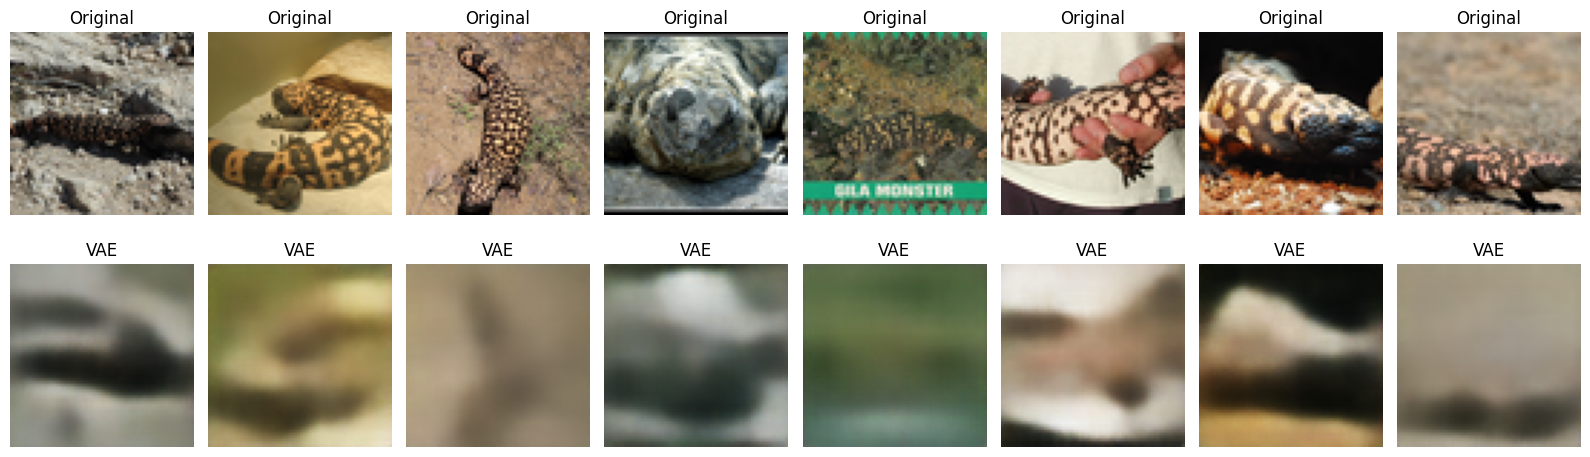

In [16]:

import torch
import matplotlib.pyplot as plt
from pathlib import Path

device = torch.device("cuda:0")
save_dir = Path("/kaggle/working/vae_results")

# 1. Load our best baseline checkpoint
checkpoint = torch.load(
    save_dir / "baseline_best.pt",
    map_location=device,
    weights_only=False
)

model = VAE(latent_dim=128).to(device)
model.load_state_dict(checkpoint["model"])
model.eval()

# 2. Take one VAL batch
x = next(iter(val_loader)).to(device)

# 3. Reconstruct images
with torch.no_grad():
    mu, logvar = model.encoder(x)
    reconstructed = model.decoder(mu)

# 4. Display original vs reconstructed
fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):

    original = x[i].cpu().permute(1, 2, 0).numpy()

    recon = reconstructed[i].cpu().permute(
        1, 2, 0
    ).numpy()

    axes[0, i].imshow(original)
    axes[0, i].set_title("Original")

    axes[1, i].imshow(recon)
    axes[1, i].set_title("VAE")

    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()

plt.savefig(
    save_dir / "baseline_reconstructions.png",
    dpi=200
)

plt.show()


In [17]:

from pathlib import Path

# Create results folder
results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Predictions required by the professor
predictions = """
# Team T23 - VAE Experiment Predictions

Study: VAE Settings
Author: [ENTER YOUR NAME]

Baseline:
Latent dimension = 128
Beta = 1.0
KL warm-up = OFF
Epochs = 20

Run 2 - Latent Dimension 64:
We predict that reducing the latent dimension
may worsen reconstruction quality.

Run 3 - Latent Dimension 256:
We predict that increasing the latent dimension
may improve reconstruction quality.

Run 4 - Beta 0.5:
We predict that reducing beta may improve
reconstruction but weaken latent regularization.

Run 5 - Beta 2.0:
We predict that increasing beta will strengthen
KL regularization but may worsen reconstruction.

Run 6 - KL Warm-up ON:
We predict that gradually increasing the KL
weight may improve the learned representation.
"""

file_path = results_dir / "predictions.md"
file_path.write_text(predictions.strip() + "\n")

print("Predictions file created!")
print("Location:", file_path)
print(file_path.read_text())


Predictions file created!
Location: /kaggle/working/results/predictions.md
# Team T23 - VAE Experiment Predictions

Study: VAE Settings
Author: [ENTER YOUR NAME]

Baseline:
Latent dimension = 128
Beta = 1.0
KL warm-up = OFF
Epochs = 20

Run 2 - Latent Dimension 64:
We predict that reducing the latent dimension
may worsen reconstruction quality.

Run 3 - Latent Dimension 256:
We predict that increasing the latent dimension
may improve reconstruction quality.

Run 4 - Beta 0.5:
We predict that reducing beta may improve
reconstruction but weaken latent regularization.

Run 5 - Beta 2.0:
We predict that increasing beta will strengthen
KL regularization but may worsen reconstruction.

Run 6 - KL Warm-up ON:
We predict that gradually increasing the KL
weight may improve the learned representation.



In [18]:

from pathlib import Path

path = Path("/kaggle/working/results/predictions.md")

content = path.read_text()
content = content.replace(
    "[ENTER YOUR NAME]",
    "Logine Ahmed Fouaad"
)

path.write_text(content)

print("Author updated successfully!")
print(path.read_text().splitlines()[3])


Author updated successfully!
Author: Logine Ahmed Fouaad


In [19]:

from pathlib import Path

folder = Path("/kaggle/working/vae_results")

for name in [
    "baseline_best.pt",
    "baseline_latest.pt",
    "baseline_history.csv"
]:
    file = folder / name
    print(name, "FOUND" if file.exists() else "MISSING")


baseline_best.pt FOUND
baseline_latest.pt FOUND
baseline_history.csv FOUND


In [2]:

import torch
import numpy as np
import pandas as pd
import random
import time
from pathlib import Path

def run_vae_experiment(name, latent_dim, beta, warmup=False):

    # Same random seed for fair comparison
    seed = 2026
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    device = torch.device("cuda:0")
    epochs = 20

    save_dir = Path("/kaggle/working/vae_results")
    save_dir.mkdir(parents=True, exist_ok=True)

    # Fresh model for this experiment
    model = VAE(latent_dim=latent_dim).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    history = []
    total_time = 0.0

    torch.cuda.reset_peak_memory_stats(device)

    for epoch in range(1, epochs + 1):

        start = time.perf_counter()
        model.train()

        # KL warm-up, only when enabled
        current_beta = (
            beta * min(1.0, epoch / 10)
            if warmup else beta
        )

        train_sum = 0.0

        for x in train_loader:

            x = x.to(device)

            optimizer.zero_grad(set_to_none=True)

            reconstruction, mu, logvar = model(x)

            loss, recon, kl = vae_loss(
                x, reconstruction, mu, logvar,
                beta=current_beta
            )

            loss.backward()
            optimizer.step()

            train_sum += loss.item() * x.size(0)

        # Validation
        model.eval()
        recon_sum = 0.0
        kl_sum = 0.0
        means = []

        with torch.no_grad():
            for x in val_loader:

                x = x.to(device)
                reconstruction, mu, logvar = model(x)

                _, recon, kl = vae_loss(
                    x, reconstruction, mu, logvar,
                    beta=1.0
                )

                recon_sum += recon.item() * x.size(0)
                kl_sum += kl.item() * x.size(0)
                means.append(mu.cpu())

        val_recon = recon_sum / len(val_dataset)
        val_kl = kl_sum / len(val_dataset)
        val_elbo = val_recon + val_kl
        val_mse = val_recon / (3 * 64 * 64)

        mu_all = torch.cat(means)

        active = int(
            (mu_all.var(0, unbiased=False) > 0.01)
            .sum().item()
        )

        torch.cuda.synchronize(device)
        elapsed = time.perf_counter() - start
        total_time += elapsed

        history.append({
            "epoch": epoch,
            "train_loss": train_sum / len(train_dataset),
            "val_reconstruction": val_recon,
            "val_mse": val_mse,
            "val_kl": val_kl,
            "val_negative_elbo": val_elbo,
            "active_units": active
        })

        # Save the best checkpoint using VAL
        best_so_far = min(
            row["val_negative_elbo"] for row in history
        )

        if val_elbo <= best_so_far:
            torch.save({
                "model": model.state_dict(),
                "latent_dim": latent_dim,
                "epoch": epoch,
                "val_negative_elbo": val_elbo
            }, save_dir / f"{name}_best.pt")

        # Save progress after each epoch
        torch.save({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "history": history,
            "training_time": total_time
        }, save_dir / f"{name}_latest.pt")

        pd.DataFrame(history).to_csv(
            save_dir / f"{name}_history.csv",
            index=False
        )

        print(
            f"{name} | Epoch {epoch:02d}/20 | "
            f"VAL MSE: {val_mse:.5f} | "
            f"KL: {val_kl:.2f} | "
            f"NegELBO: {val_elbo:.2f} | "
            f"Active: {active}"
        )

    print("\nEXPERIMENT COMPLETED:", name)
    print("Training time:", round(total_time, 2), "seconds")
    print(
        "Peak GPU memory:",
        round(torch.cuda.max_memory_allocated(device) / 1e6, 2),
        "MB"
    )

    return history


In [9]:

import torch
import numpy as np
import pandas as pd
import random
import time
from pathlib import Path

def run_vae_experiment(name, latent_dim, beta, warmup=False):

    # Same random seed for fair comparison
    seed = 2026
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    device = torch.device("cuda:0")
    epochs = 20

    save_dir = Path("/kaggle/working/vae_results")
    save_dir.mkdir(parents=True, exist_ok=True)

    # Fresh model for this experiment
    model = VAE(latent_dim=latent_dim).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    history = []
    total_time = 0.0

    torch.cuda.reset_peak_memory_stats(device)

    for epoch in range(1, epochs + 1):

        start = time.perf_counter()
        model.train()

        # KL warm-up, only when enabled
        current_beta = (
            beta * min(1.0, epoch / 10)
            if warmup else beta
        )

        train_sum = 0.0

        for x in train_loader:

            x = x.to(device)

            optimizer.zero_grad(set_to_none=True)

            reconstruction, mu, logvar = model(x)

            loss, recon, kl = vae_loss(
                x, reconstruction, mu, logvar,
                beta=current_beta
            )

            loss.backward()
            optimizer.step()

            train_sum += loss.item() * x.size(0)

        # Validation
        model.eval()
        recon_sum = 0.0
        kl_sum = 0.0
        means = []

        with torch.no_grad():
            for x in val_loader:

                x = x.to(device)
                reconstruction, mu, logvar = model(x)

                _, recon, kl = vae_loss(
                    x, reconstruction, mu, logvar,
                    beta=1.0
                )

                recon_sum += recon.item() * x.size(0)
                kl_sum += kl.item() * x.size(0)
                means.append(mu.cpu())

        val_recon = recon_sum / len(val_dataset)
        val_kl = kl_sum / len(val_dataset)
        val_elbo = val_recon + val_kl
        val_mse = val_recon / (3 * 64 * 64)

        mu_all = torch.cat(means)

        active = int(
            (mu_all.var(0, unbiased=False) > 0.01)
            .sum().item()
        )

        torch.cuda.synchronize(device)
        elapsed = time.perf_counter() - start
        total_time += elapsed

        history.append({
            "epoch": epoch,
            "train_loss": train_sum / len(train_dataset),
            "val_reconstruction": val_recon,
            "val_mse": val_mse,
            "val_kl": val_kl,
            "val_negative_elbo": val_elbo,
            "active_units": active
        })

        # Save the best checkpoint using VAL
        best_so_far = min(
            row["val_negative_elbo"] for row in history
        )

        if val_elbo <= best_so_far:
            torch.save({
                "model": model.state_dict(),
                "latent_dim": latent_dim,
                "epoch": epoch,
                "val_negative_elbo": val_elbo
            }, save_dir / f"{name}_best.pt")

        # Save progress after each epoch
        torch.save({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "history": history,
            "training_time": total_time
        }, save_dir / f"{name}_latest.pt")

        pd.DataFrame(history).to_csv(
            save_dir / f"{name}_history.csv",
            index=False
        )

        print(
            f"{name} | Epoch {epoch:02d}/20 | "
            f"VAL MSE: {val_mse:.5f} | "
            f"KL: {val_kl:.2f} | "
            f"NegELBO: {val_elbo:.2f} | "
            f"Active: {active}"
        )

    print("\nEXPERIMENT COMPLETED:", name)
    print("Training time:", round(total_time, 2), "seconds")
    print(
        "Peak GPU memory:",
        round(torch.cuda.max_memory_allocated(device) / 1e6, 2),
        "MB"
    )

    return history


In [10]:
print("Kaggle is working!")

Kaggle is working!


In [12]:

import torch
import numpy as np
import pandas as pd
import random
import time
from pathlib import Path

def run_vae_experiment(name, latent_dim, beta, warmup=False):

    # Same random seed for fair comparison
    seed = 2026
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    device = torch.device("cuda:0")
    epochs = 20

    save_dir = Path("/kaggle/working/vae_results")
    save_dir.mkdir(parents=True, exist_ok=True)

    # Fresh model for this experiment
    model = VAE(latent_dim=latent_dim).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    history = []
    total_time = 0.0

    torch.cuda.reset_peak_memory_stats(device)

    for epoch in range(1, epochs + 1):

        start = time.perf_counter()
        model.train()

        # KL warm-up, only when enabled
        current_beta = (
            beta * min(1.0, epoch / 10)
            if warmup else beta
        )

        train_sum = 0.0

        for x in train_loader:

            x = x.to(device)

            optimizer.zero_grad(set_to_none=True)

            reconstruction, mu, logvar = model(x)

            loss, recon, kl = vae_loss(
                x, reconstruction, mu, logvar,
                beta=current_beta
            )

            loss.backward()
            optimizer.step()

            train_sum += loss.item() * x.size(0)

        # Validation
        model.eval()
        recon_sum = 0.0
        kl_sum = 0.0
        means = []

        with torch.no_grad():
            for x in val_loader:

                x = x.to(device)
                reconstruction, mu, logvar = model(x)

                _, recon, kl = vae_loss(
                    x, reconstruction, mu, logvar,
                    beta=1.0
                )

                recon_sum += recon.item() * x.size(0)
                kl_sum += kl.item() * x.size(0)
                means.append(mu.cpu())

        val_recon = recon_sum / len(val_dataset)
        val_kl = kl_sum / len(val_dataset)
        val_elbo = val_recon + val_kl
        val_mse = val_recon / (3 * 64 * 64)

        mu_all = torch.cat(means)

        active = int(
            (mu_all.var(0, unbiased=False) > 0.01)
            .sum().item()
        )

        torch.cuda.synchronize(device)
        elapsed = time.perf_counter() - start
        total_time += elapsed

        history.append({
            "epoch": epoch,
            "train_loss": train_sum / len(train_dataset),
            "val_reconstruction": val_recon,
            "val_mse": val_mse,
            "val_kl": val_kl,
            "val_negative_elbo": val_elbo,
            "active_units": active
        })

        # Save the best checkpoint using VAL
        best_so_far = min(
            row["val_negative_elbo"] for row in history
        )

        if val_elbo <= best_so_far:
            torch.save({
                "model": model.state_dict(),
                "latent_dim": latent_dim,
                "epoch": epoch,
                "val_negative_elbo": val_elbo
            }, save_dir / f"{name}_best.pt")

        # Save progress after each epoch
        torch.save({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "history": history,
            "training_time": total_time
        }, save_dir / f"{name}_latest.pt")

        pd.DataFrame(history).to_csv(
            save_dir / f"{name}_history.csv",
            index=False
        )

        print(
            f"{name} | Epoch {epoch:02d}/20 | "
            f"VAL MSE: {val_mse:.5f} | "
            f"KL: {val_kl:.2f} | "
            f"NegELBO: {val_elbo:.2f} | "
            f"Active: {active}"
        )

    print("\nEXPERIMENT COMPLETED:", name)
    print("Training time:", round(total_time, 2), "seconds")
    print(
        "Peak GPU memory:",
        round(torch.cuda.max_memory_allocated(device) / 1e6, 2),
        "MB"
    )

    return history


In [13]:

needed = [
    "VAE",
    "vae_loss",
    "train_loader",
    "val_loader",
    "train_dataset",
    "val_dataset",
    "run_vae_experiment"
]

for name in needed:
    print(
        name,
        "READY" if name in globals() else "MISSING"
    )


VAE MISSING
vae_loss MISSING
train_loader MISSING
val_loader MISSING
train_dataset MISSING
val_dataset MISSING
run_vae_experiment READY


In [14]:
needed = [
    "VAE", "vae_loss",
    "train_loader", "val_loader",
    "train_dataset", "val_dataset",
    "run_vae_experiment"
]

for name in needed:
    print(name, "READY" if name in globals() else "MISSING")

VAE MISSING
vae_loss MISSING
train_loader MISSING
val_loader MISSING
train_dataset MISSING
val_dataset MISSING
run_vae_experiment READY


In [15]:
class ImageNetVAEDataset(Dataset):

_IncompleteInputError: incomplete input (1679002123.py, line 1)

In [16]:

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

# Load our saved dataset
folder = Path(
    "/kaggle/input/notebooks/hopecleg/"
    "t23-imagenet-dataset-preparation/t23_dataset"
)

X = np.load(folder / "images.npy", mmap_mode="r")
train_idx = np.load(folder / "train_indices.npy")
val_idx = np.load(folder / "val_indices.npy")

# Define the complete Dataset class
class ImageNetVAEDataset(Dataset):

    def __init__(self, images, indices):
        self.images = images
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image = np.array(
            self.images[self.indices[idx]],
            copy=True
        )

        image = torch.from_numpy(image)
        image = image.permute(2, 0, 1)
        image = image.float() / 255.0

        return image

# Create TRAIN and VAL datasets
train_dataset = ImageNetVAEDataset(X, train_idx)
val_dataset = ImageNetVAEDataset(X, val_idx)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Test one batch
batch = next(iter(train_loader))

print("TRAIN:", len(train_dataset))
print("VAL:", len(val_dataset))
print("Batch shape:", batch.shape)


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/notebooks/hopecleg/t23-imagenet-dataset-preparation/t23_dataset/images.npy'

In [17]:

from pathlib import Path

root = Path("/kaggle/input/notebooks")

print("Checking saved notebook outputs...")

if root.exists():
    for owner in root.iterdir():
        if owner.is_dir():
            for notebook in owner.iterdir():
                if notebook.is_dir():
                    print("Notebook:", notebook.name)

                    dataset = notebook / "t23_dataset"
                    print("Dataset folder:", dataset.exists())

                    if dataset.exists():
                        print("Images file:", 
                              (dataset / "images.npy").exists())
                        print("Path:", dataset)
else:
    print("Notebook inputs not mounted")


Checking saved notebook outputs...
Notebook: t23-imagenet-dataset-preparation
Dataset folder: False


In [18]:

from pathlib import Path

root = Path(
    "/kaggle/input/notebooks/hopecleg/"
    "t23-imagenet-dataset-preparation"
)

print("Notebook folder exists:", root.exists())

if root.exists():
    for item in root.iterdir():
        print(item.name)


Notebook folder exists: True
.virtual_documents
__notebook__.ipynb
__output__.json
__results__.html
__results___files
custom.css
results
vae_results


In [21]:

from pathlib import Path

root = Path(
    "/kaggle/input/notebooks/hopecleg/"
    "t23-imagenet-dataset-preparation"
)

print("Dataset available:",
      (root / "t23_dataset/images.npy").exists())


Dataset available: False


In [22]:

from pathlib import Path
import numpy as np

# Check the new Kaggle Dataset location
root = Path(
    "/kaggle/input/datasets/hopecleg/"
    "t23-imagenet-64x64-processed"
)

print("New dataset folder exists:", root.exists())

if root.exists():
    print("\nFiles and folders:")
    for item in root.iterdir():
        print(item.name)

    # Check both possible image locations
    candidates = [
        root / "images.npy",
        root / "t23_dataset" / "images.npy"
    ]

    for path in candidates:
        print("\nChecking:", path)
        print("Exists:", path.exists())

        if path.exists():
            X = np.load(path, mmap_mode="r")
            print("Images shape:", X.shape)
            print("DATASET FOUND!")
else:
    print("Dataset is not mounted at this path")


New dataset folder exists: True

Files and folders:
.virtual_documents
t23_dataset

Checking: /kaggle/input/datasets/hopecleg/t23-imagenet-64x64-processed/images.npy
Exists: False

Checking: /kaggle/input/datasets/hopecleg/t23-imagenet-64x64-processed/t23_dataset/images.npy
Exists: True
Images shape: (13270, 64, 64, 3)
DATASET FOUND!


In [23]:

from pathlib import Path

folder = Path(
    "/kaggle/input/datasets/hopecleg/"
    "t23-imagenet-64x64-processed/"
    "t23_dataset"
)

print("Dataset available:", (folder / "images.npy").exists())


Dataset available: True


In [25]:

from pathlib import Path

folder = Path(
    "/kaggle/input/notebooks/hopecleg/"
    "t23-imagenet-dataset-preparation/vae_results"
)

for name in [
    "baseline_best.pt",
    "baseline_latest.pt",
    "baseline_history.csv",
    "baseline_reconstructions.png"
]:
    print(
        name,
        "FOUND" if (folder / name).exists() else "MISSING"
    )


baseline_best.pt FOUND
baseline_latest.pt FOUND
baseline_history.csv FOUND
baseline_reconstructions.png FOUND


In [24]:

from pathlib import Path

folder = Path(
    "/kaggle/input/datasets/hopecleg/"
    "t23-imagenet-64x64-processed/"
    "t23_dataset"
)

print("Dataset available:", (folder / "images.npy").exists())


Dataset available: True


In [26]:

import torch

needed = [
    "VAE",
    "vae_loss",
    "train_loader",
    "val_loader",
    "train_dataset",
    "val_dataset",
    "run_vae_experiment"
]

for name in needed:
    print(name, "READY" if name in globals() else "MISSING")

print("GPU available:", torch.cuda.is_available())


VAE MISSING
vae_loss MISSING
train_loader MISSING
val_loader MISSING
train_dataset MISSING
val_dataset MISSING
run_vae_experiment READY
GPU available: True


In [27]:

import torch
import torch.nn as nn
import numpy as np
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

# 1. Load our saved dataset
folder = Path(
    "/kaggle/input/datasets/hopecleg/"
    "t23-imagenet-64x64-processed/t23_dataset"
)

X = np.load(folder / "images.npy", mmap_mode="r")
train_idx = np.load(folder / "train_indices.npy")
val_idx = np.load(folder / "val_indices.npy")

# 2. Prepare images for PyTorch
class ImageNetVAEDataset(Dataset):
    def __init__(self, images, indices):
        self.images = images
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image = np.array(
            self.images[self.indices[idx]], copy=True
        )
        image = torch.from_numpy(image)
        return image.permute(2, 0, 1).float() / 255.0

train_dataset = ImageNetVAEDataset(X, train_idx)
val_dataset = ImageNetVAEDataset(X, val_idx)

train_loader = DataLoader(
    train_dataset, batch_size=64,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=64,
    shuffle=False, num_workers=2, pin_memory=True
)

# 3. Encoder
class VAEEncoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(128, 256, 4, 2, 1), nn.ReLU()
        )
        self.fc_mu = nn.Linear(4096, latent_dim)
        self.fc_logvar = nn.Linear(4096, latent_dim)

    def forward(self, x):
        h = self.features(x).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)

# 4. Decoder
class VAEDecoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 4096)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Sigmoid()
        )

    def forward(self, z):
        h = self.fc(z).view(-1, 256, 4, 4)
        return self.decoder(h)

# 5. Complete VAE
class VAE(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.encoder = VAEEncoder(latent_dim)
        self.decoder = VAEDecoder(latent_dim)

    def forward(self, x):
        mu, logvar = self.encoder(x)
        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std
        return self.decoder(z), mu, logvar

# 6. Loss function
def vae_loss(x, reconstruction, mu, logvar, beta=1.0):
    recon = (
        (reconstruction - x).pow(2)
        .flatten(1).sum(1).mean()
    )

    kl = -0.5 * (
        1 + logvar - mu.pow(2) - logvar.exp()
    ).sum(1).mean()

    return recon + beta * kl, recon, kl

# 7. Verify
print("TRAIN:", len(train_dataset))
print("VAL:", len(val_dataset))
print("GPU:", torch.cuda.is_available())
print("VAE components restored successfully!")


TRAIN: 11493
VAL: 1277
GPU: True
VAE components restored successfully!


In [28]:

history_64 = run_vae_experiment(
    name="latent64",
    latent_dim=64,
    beta=1.0,
    warmup=False
)


KeyboardInterrupt: 

In [29]:

import torch

print("GPU:", torch.cuda.is_available())

print("VAE:", "VAE" in globals())
print("DataLoader:", "train_loader" in globals())
print("Experiment function:",
      "run_vae_experiment" in globals())

print("Ready for testing!")


GPU: True
VAE: True
DataLoader: True
Experiment function: True
Ready for testing!


In [32]:

from torch.utils.data import DataLoader

# Recreate loaders without multiprocessing
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Test loading one batch
import time

start = time.time()
batch = next(iter(train_loader))

print("Batch shape:", batch.shape)
print("Loading time:", round(time.time() - start, 2), "seconds")
print("DataLoader is working!")


Batch shape: torch.Size([64, 3, 64, 64])
Loading time: 1.12 seconds
DataLoader is working!


In [ ]:

history_64 = run_vae_experiment(
    name="latent64",
    latent_dim=64,
    beta=1.0,
    warmup=False
)


In [33]:

import time

print("TEST STARTED", flush=True)

start = time.time()

image = train_dataset[0]

print("One image loaded!", flush=True)
print("Image shape:", image.shape)
print("Time:", round(time.time() - start, 2))


TEST STARTED
One image loaded!
Image shape: torch.Size([3, 64, 64])
Time: 0.0


In [34]:

import time
from torch.utils.data import DataLoader

# Use one process to avoid multiprocessing issues
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Starting batch test...", flush=True)

start = time.time()
batch = next(iter(train_loader))

print("Batch loaded successfully!")
print("Batch shape:", batch.shape)
print("Loading time:", round(time.time() - start, 2), "seconds")


Starting batch test...
Batch loaded successfully!
Batch shape: torch.Size([64, 3, 64, 64])
Loading time: 0.4 seconds


In [35]:

from torch.utils.data import DataLoader

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("TRAIN batches:", len(train_loader))
print("VAL batches:", len(val_loader))
print("Ready for Experiment 2!")


TRAIN batches: 180
VAL batches: 20
Ready for Experiment 2!


In [36]:

history_64 = run_vae_experiment(
    name="latent64",
    latent_dim=64,
    beta=1.0,
    warmup=False
)


latent64 | Epoch 01/20 | VAL MSE: 0.03133 | KL: 36.74 | NegELBO: 421.73 | Active: 64
latent64 | Epoch 02/20 | VAL MSE: 0.02734 | KL: 37.16 | NegELBO: 373.10 | Active: 64
latent64 | Epoch 03/20 | VAL MSE: 0.02281 | KL: 42.31 | NegELBO: 322.65 | Active: 64
latent64 | Epoch 04/20 | VAL MSE: 0.02117 | KL: 46.71 | NegELBO: 306.79 | Active: 64
latent64 | Epoch 05/20 | VAL MSE: 0.02033 | KL: 46.47 | NegELBO: 296.27 | Active: 64
latent64 | Epoch 06/20 | VAL MSE: 0.01967 | KL: 49.97 | NegELBO: 291.67 | Active: 64
latent64 | Epoch 07/20 | VAL MSE: 0.01938 | KL: 49.82 | NegELBO: 287.99 | Active: 63
latent64 | Epoch 08/20 | VAL MSE: 0.01910 | KL: 48.76 | NegELBO: 283.52 | Active: 63
latent64 | Epoch 09/20 | VAL MSE: 0.01891 | KL: 54.61 | NegELBO: 287.00 | Active: 64
latent64 | Epoch 10/20 | VAL MSE: 0.01861 | KL: 51.79 | NegELBO: 280.52 | Active: 64
latent64 | Epoch 11/20 | VAL MSE: 0.01822 | KL: 55.61 | NegELBO: 279.52 | Active: 64
latent64 | Epoch 12/20 | VAL MSE: 0.01819 | KL: 54.69 | NegELBO: 

In [37]:

history_256 = run_vae_experiment(
    name="latent256",
    latent_dim=256,
    beta=1.0,
    warmup=False
)


latent256 | Epoch 01/20 | VAL MSE: 0.03359 | KL: 43.50 | NegELBO: 456.31 | Active: 256
latent256 | Epoch 02/20 | VAL MSE: 0.02943 | KL: 47.06 | NegELBO: 408.75 | Active: 256
latent256 | Epoch 03/20 | VAL MSE: 0.02455 | KL: 48.96 | NegELBO: 350.60 | Active: 256
latent256 | Epoch 04/20 | VAL MSE: 0.02296 | KL: 48.62 | NegELBO: 330.73 | Active: 256
latent256 | Epoch 05/20 | VAL MSE: 0.02169 | KL: 47.02 | NegELBO: 313.58 | Active: 256
latent256 | Epoch 06/20 | VAL MSE: 0.02090 | KL: 49.21 | NegELBO: 306.06 | Active: 255
latent256 | Epoch 07/20 | VAL MSE: 0.02031 | KL: 49.33 | NegELBO: 298.96 | Active: 254
latent256 | Epoch 08/20 | VAL MSE: 0.01994 | KL: 51.57 | NegELBO: 296.60 | Active: 252
latent256 | Epoch 09/20 | VAL MSE: 0.01932 | KL: 52.31 | NegELBO: 289.74 | Active: 254
latent256 | Epoch 10/20 | VAL MSE: 0.01887 | KL: 53.16 | NegELBO: 285.06 | Active: 253
latent256 | Epoch 11/20 | VAL MSE: 0.01883 | KL: 54.27 | NegELBO: 285.62 | Active: 253
latent256 | Epoch 12/20 | VAL MSE: 0.01855 

In [38]:

history_beta05 = run_vae_experiment(
    name="beta05",
    latent_dim=128,
    beta=0.5,
    warmup=False
)


beta05 | Epoch 01/20 | VAL MSE: 0.03242 | KL: 56.29 | NegELBO: 454.66 | Active: 128
beta05 | Epoch 02/20 | VAL MSE: 0.02641 | KL: 62.59 | NegELBO: 387.14 | Active: 128
beta05 | Epoch 03/20 | VAL MSE: 0.02195 | KL: 68.50 | NegELBO: 338.21 | Active: 128
beta05 | Epoch 04/20 | VAL MSE: 0.02007 | KL: 71.36 | NegELBO: 317.97 | Active: 128
beta05 | Epoch 05/20 | VAL MSE: 0.01909 | KL: 70.84 | NegELBO: 305.37 | Active: 128
beta05 | Epoch 06/20 | VAL MSE: 0.01835 | KL: 74.15 | NegELBO: 299.65 | Active: 128
beta05 | Epoch 07/20 | VAL MSE: 0.01799 | KL: 71.84 | NegELBO: 292.93 | Active: 128
beta05 | Epoch 08/20 | VAL MSE: 0.01744 | KL: 75.90 | NegELBO: 290.15 | Active: 128
beta05 | Epoch 09/20 | VAL MSE: 0.01733 | KL: 75.82 | NegELBO: 288.71 | Active: 128
beta05 | Epoch 10/20 | VAL MSE: 0.01696 | KL: 80.41 | NegELBO: 288.84 | Active: 127
beta05 | Epoch 11/20 | VAL MSE: 0.01625 | KL: 82.86 | NegELBO: 282.56 | Active: 127
beta05 | Epoch 12/20 | VAL MSE: 0.01602 | KL: 80.57 | NegELBO: 277.39 | Acti

In [39]:

history_beta2 = run_vae_experiment(
    name="beta2",
    latent_dim=128,
    beta=2.0,
    warmup=False
)


beta2 | Epoch 01/20 | VAL MSE: 0.03482 | KL: 25.12 | NegELBO: 452.97 | Active: 128
beta2 | Epoch 02/20 | VAL MSE: 0.02964 | KL: 26.51 | NegELBO: 390.68 | Active: 128
beta2 | Epoch 03/20 | VAL MSE: 0.02757 | KL: 27.00 | NegELBO: 365.82 | Active: 128
beta2 | Epoch 04/20 | VAL MSE: 0.02440 | KL: 29.91 | NegELBO: 329.73 | Active: 128
beta2 | Epoch 05/20 | VAL MSE: 0.02344 | KL: 29.85 | NegELBO: 317.83 | Active: 128
beta2 | Epoch 06/20 | VAL MSE: 0.02266 | KL: 31.88 | NegELBO: 310.38 | Active: 128
beta2 | Epoch 07/20 | VAL MSE: 0.02230 | KL: 32.50 | NegELBO: 306.53 | Active: 128
beta2 | Epoch 08/20 | VAL MSE: 0.02203 | KL: 32.79 | NegELBO: 303.46 | Active: 128
beta2 | Epoch 09/20 | VAL MSE: 0.02187 | KL: 32.73 | NegELBO: 301.50 | Active: 128
beta2 | Epoch 10/20 | VAL MSE: 0.02181 | KL: 33.36 | NegELBO: 301.42 | Active: 128
beta2 | Epoch 11/20 | VAL MSE: 0.02130 | KL: 34.84 | NegELBO: 296.53 | Active: 128
beta2 | Epoch 12/20 | VAL MSE: 0.02126 | KL: 35.00 | NegELBO: 296.23 | Active: 128
beta

In [40]:

history_warmup = run_vae_experiment(
    name="kl_warmup",
    latent_dim=128,
    beta=1.0,
    warmup=True
)


kl_warmup | Epoch 01/20 | VAL MSE: 0.02916 | KL: 133.59 | NegELBO: 491.89 | Active: 128
kl_warmup | Epoch 02/20 | VAL MSE: 0.02420 | KL: 115.51 | NegELBO: 412.94 | Active: 128
kl_warmup | Epoch 03/20 | VAL MSE: 0.02029 | KL: 104.15 | NegELBO: 353.46 | Active: 128
kl_warmup | Epoch 04/20 | VAL MSE: 0.01909 | KL: 90.15 | NegELBO: 324.72 | Active: 128
kl_warmup | Epoch 05/20 | VAL MSE: 0.01864 | KL: 79.25 | NegELBO: 308.31 | Active: 128
kl_warmup | Epoch 06/20 | VAL MSE: 0.01819 | KL: 75.16 | NegELBO: 298.74 | Active: 128
kl_warmup | Epoch 07/20 | VAL MSE: 0.01819 | KL: 74.03 | NegELBO: 297.59 | Active: 128
kl_warmup | Epoch 08/20 | VAL MSE: 0.01784 | KL: 68.35 | NegELBO: 287.53 | Active: 128
kl_warmup | Epoch 09/20 | VAL MSE: 0.01782 | KL: 65.76 | NegELBO: 284.76 | Active: 126
kl_warmup | Epoch 10/20 | VAL MSE: 0.01779 | KL: 61.93 | NegELBO: 280.58 | Active: 126
kl_warmup | Epoch 11/20 | VAL MSE: 0.01759 | KL: 61.42 | NegELBO: 277.53 | Active: 126
kl_warmup | Epoch 12/20 | VAL MSE: 0.017

In [41]:

import pandas as pd
from pathlib import Path

# Experiment results folder
folder = Path("/kaggle/working/vae_results")

experiments = [
    ("Baseline", "baseline", 128, 1.0, "OFF"),
    ("Latent 64", "latent64", 64, 1.0, "OFF"),
    ("Latent 256", "latent256", 256, 1.0, "OFF"),
    ("Beta 0.5", "beta05", 128, 0.5, "OFF"),
    ("Beta 2.0", "beta2", 128, 2.0, "OFF"),
    ("KL Warm-up", "kl_warmup", 128, 1.0, "ON")
]

results = []

for name, file_name, latent, beta, warmup in experiments:

    path = folder / f"{file_name}_history.csv"

    row = {
        "Experiment": name,
        "Latent Dimension": latent,
        "Beta": beta,
        "KL Warm-up": warmup,
        "Epochs": None,
        "VAL MSE": None,
        "VAL KL": None,
        "VAL Negative ELBO": None,
        "Active Units": None
    }

    if path.exists():
        history = pd.read_csv(path)
        final = history.iloc[-1]

        row["Epochs"] = int(final["epoch"])

        mse_col = (
            "val_mse_per_pixel"
            if "val_mse_per_pixel" in history.columns
            else "val_mse"
        )

        row["VAL MSE"] = final[mse_col]
        row["VAL KL"] = final["val_kl"]
        row["VAL Negative ELBO"] = final["val_negative_elbo"]
        row["Active Units"] = int(final["active_units"])

    results.append(row)

results_df = pd.DataFrame(results)

# Save comparison table
output = Path("/kaggle/working/results")
output.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    output / "vae_experiment_comparison.csv",
    index=False
)

print("VAE Comparison Table:")
print(results_df.to_string(index=False))

print("\nSaved to:")
print(output / "vae_experiment_comparison.csv")


VAE Comparison Table:
Experiment  Latent Dimension  Beta KL Warm-up  Epochs  VAL MSE    VAL KL  VAL Negative ELBO  Active Units
  Baseline               128   1.0        OFF     NaN      NaN       NaN                NaN           NaN
 Latent 64                64   1.0        OFF    20.0 0.017074 59.639558         269.443331          63.0
Latent 256               256   1.0        OFF    20.0 0.017394 59.162183         272.904196         255.0
  Beta 0.5               128   0.5        OFF    20.0 0.014849 92.045294         274.505776         127.0
  Beta 2.0               128   2.0        OFF    20.0 0.020422 36.517177         287.466751         127.0
KL Warm-up               128   1.0         ON    20.0 0.016602 63.514199         267.514929         126.0

Saved to:
/kaggle/working/results/vae_experiment_comparison.csv


In [42]:

import pandas as pd
from pathlib import Path

# Open our saved comparison table
file = Path(
    "/kaggle/working/results/vae_experiment_comparison.csv"
)

df = pd.read_csv(file)

# Rename experiments
df["Experiment"] = [
    "Exp 1",
    "Exp 2",
    "Exp 3",
    "Exp 4",
    "Exp 5",
    "Exp 6"
]

# Add description of the change
df.insert(1, "Change", [
    "Baseline (Latent=128, Beta=1)",
    "Latent dimension: 128 to 64",
    "Latent dimension: 128 to 256",
    "Beta: 1 to 0.5",
    "Beta: 1 to 2",
    "KL Warm-up: OFF to ON"
])

# Save updated CSV
df.to_csv(file, index=False)

print(df.to_string(index=False))
print("\nUpdated table saved successfully!")


Experiment                        Change  Latent Dimension  Beta KL Warm-up  Epochs  VAL MSE    VAL KL  VAL Negative ELBO  Active Units
     Exp 1 Baseline (Latent=128, Beta=1)               128   1.0        OFF     NaN      NaN       NaN                NaN           NaN
     Exp 2   Latent dimension: 128 to 64                64   1.0        OFF    20.0 0.017074 59.639558         269.443331          63.0
     Exp 3  Latent dimension: 128 to 256               256   1.0        OFF    20.0 0.017394 59.162183         272.904196         255.0
     Exp 4                Beta: 1 to 0.5               128   0.5        OFF    20.0 0.014849 92.045294         274.505776         127.0
     Exp 5                  Beta: 1 to 2               128   2.0        OFF    20.0 0.020422 36.517177         287.466751         127.0
     Exp 6         KL Warm-up: OFF to ON               128   1.0         ON    20.0 0.016602 63.514199         267.514929         126.0

Updated table saved successfully!


In [43]:

from pathlib import Path

folder = Path("/kaggle/working/vae_results")

names = {
    "latent64": "exp2_latent64",
    "latent256": "exp3_latent256",
    "beta05": "exp4_beta05",
    "beta2": "exp5_beta2",
    "kl_warmup": "exp6_kl_warmup"
}

for old_name, new_name in names.items():

    for suffix in ["best.pt", "latest.pt", "history.csv"]:

        old_file = folder / f"{old_name}_{suffix}"
        new_file = folder / f"{new_name}_{suffix}"

        if old_file.exists():
            old_file.rename(new_file)
            print(old_file.name, "->", new_file.name)

print("\nOutput files renamed successfully!")


latent64_best.pt -> exp2_latent64_best.pt
latent64_latest.pt -> exp2_latent64_latest.pt
latent64_history.csv -> exp2_latent64_history.csv
latent256_best.pt -> exp3_latent256_best.pt
latent256_latest.pt -> exp3_latent256_latest.pt
latent256_history.csv -> exp3_latent256_history.csv
beta05_best.pt -> exp4_beta05_best.pt
beta05_latest.pt -> exp4_beta05_latest.pt
beta05_history.csv -> exp4_beta05_history.csv
beta2_best.pt -> exp5_beta2_best.pt
beta2_latest.pt -> exp5_beta2_latest.pt
beta2_history.csv -> exp5_beta2_history.csv
kl_warmup_best.pt -> exp6_kl_warmup_best.pt
kl_warmup_latest.pt -> exp6_kl_warmup_latest.pt
kl_warmup_history.csv -> exp6_kl_warmup_history.csv

Output files renamed successfully!


In [44]:

from pathlib import Path
import shutil

# Saved Experiment 1 files
source = Path(
    "/kaggle/input/notebooks/hopecleg/"
    "t23-imagenet-dataset-preparation/vae_results"
)

# Current experiments folder
destination = Path("/kaggle/working/vae_results")
destination.mkdir(parents=True, exist_ok=True)

files = {
    "baseline_best.pt": "exp1_baseline_best.pt",
    "baseline_latest.pt": "exp1_baseline_latest.pt",
    "baseline_history.csv": "exp1_baseline_history.csv",
    "baseline_reconstructions.png":
        "exp1_baseline_reconstructions.png"
}

for old_name, new_name in files.items():
    source_file = source / old_name
    dest_file = destination / new_name

    if source_file.exists():
        shutil.copy2(source_file, dest_file)
        print("COPIED:", new_name)
    else:
        print("MISSING:", old_name)

print("\nExperiment 1 copying finished!")


COPIED: exp1_baseline_best.pt
COPIED: exp1_baseline_latest.pt
COPIED: exp1_baseline_history.csv
COPIED: exp1_baseline_reconstructions.png

Experiment 1 copying finished!


In [45]:

import pandas as pd
from pathlib import Path

folder = Path("/kaggle/working")

table_path = folder / "results/vae_experiment_comparison.csv"
baseline_path = folder / "vae_results/exp1_baseline_history.csv"

df = pd.read_csv(table_path)
baseline = pd.read_csv(baseline_path)

# Get final epoch of Experiment 1
last = baseline.iloc[-1]

# Fill the missing baseline row
mask = df["Experiment"] == "Exp 1"

df.loc[mask, "Epochs"] = int(last["epoch"])
df.loc[mask, "VAL MSE"] = last["val_mse_per_pixel"]
df.loc[mask, "VAL KL"] = last["val_kl"]
df.loc[mask, "VAL Negative ELBO"] = last["val_negative_elbo"]
df.loc[mask, "Active Units"] = int(last["active_units"])

# Save the corrected table
df.to_csv(table_path, index=False)

print(df.to_string(index=False))
print("\nMissing values:", df.isna().sum().sum())
print("Final results table updated!")


Experiment                        Change  Latent Dimension  Beta KL Warm-up  Epochs  VAL MSE    VAL KL  VAL Negative ELBO  Active Units
     Exp 1 Baseline (Latent=128, Beta=1)               128   1.0        OFF    20.0 0.017029 60.953118         270.211533         125.0
     Exp 2   Latent dimension: 128 to 64                64   1.0        OFF    20.0 0.017074 59.639558         269.443331          63.0
     Exp 3  Latent dimension: 128 to 256               256   1.0        OFF    20.0 0.017394 59.162183         272.904196         255.0
     Exp 4                Beta: 1 to 0.5               128   0.5        OFF    20.0 0.014849 92.045294         274.505776         127.0
     Exp 5                  Beta: 1 to 2               128   2.0        OFF    20.0 0.020422 36.517177         287.466751         127.0
     Exp 6         KL Warm-up: OFF to ON               128   1.0         ON    20.0 0.016602 63.514199         267.514929         126.0

Missing values: 0
Final results table updated!


In [46]:

import pandas as pd
from pathlib import Path

folder = Path("/kaggle/working/vae_results")

experiments = {
    "Exp 1": "exp1_baseline",
    "Exp 2": "exp2_latent64",
    "Exp 3": "exp3_latent256",
    "Exp 4": "exp4_beta05",
    "Exp 5": "exp5_beta2",
    "Exp 6": "exp6_kl_warmup"
}

rows = []

for exp, prefix in experiments.items():
    history = pd.read_csv(
        folder / f"{prefix}_history.csv"
    )

    best = history.loc[
        history["val_negative_elbo"].idxmin()
    ]

    mse_col = (
        "val_mse_per_pixel"
        if "val_mse_per_pixel" in history.columns
        else "val_mse"
    )

    rows.append({
        "Experiment": exp,
        "Best Epoch": int(best["epoch"]),
        "Best VAL MSE": best[mse_col],
        "Best VAL KL": best["val_kl"],
        "Best VAL Negative ELBO":
            best["val_negative_elbo"],
        "Active Units": int(best["active_units"])
    })

best_df = pd.DataFrame(rows)

best_df = best_df.sort_values(
    "Best VAL Negative ELBO"
)

output = Path("/kaggle/working/results")
output.mkdir(parents=True, exist_ok=True)

best_df.to_csv(
    output / "vae_best_checkpoint_comparison.csv",
    index=False
)

print(best_df.to_string(index=False))

print("\nBEST VAE:", best_df.iloc[0]["Experiment"])
print("Best checkpoint comparison saved!")


Experiment  Best Epoch  Best VAL MSE  Best VAL KL  Best VAL Negative ELBO  Active Units
     Exp 6          20      0.016602    63.514199              267.514929           126
     Exp 2          20      0.017074    59.639558              269.443331            63
     Exp 1          20      0.017029    60.953118              270.211533           125
     Exp 4          19      0.015006    88.095231              272.487074           127
     Exp 3          18      0.017401    59.025991              272.846067           255
     Exp 5          20      0.020422    36.517177              287.466751           127

BEST VAE: Exp 6
Best checkpoint comparison saved!


In [47]:

from pathlib import Path
import shutil

folder = Path("/kaggle/working/vae_results")

source = folder / "exp6_kl_warmup_best.pt"
destination = folder / "T23_BEST_VAE.pt"

assert source.exists(), "Exp 6 checkpoint not found!"

shutil.copy2(source, destination)

print("BEST VAE SAVED!")
print("Selected experiment: Exp 6")
print("Model file:", destination)
print("Size:", round(destination.stat().st_size / 1e6, 2), "MB")


BEST VAE SAVED!
Selected experiment: Exp 6
Model file: /kaggle/working/vae_results/T23_BEST_VAE.pt
Size: 11.84 MB


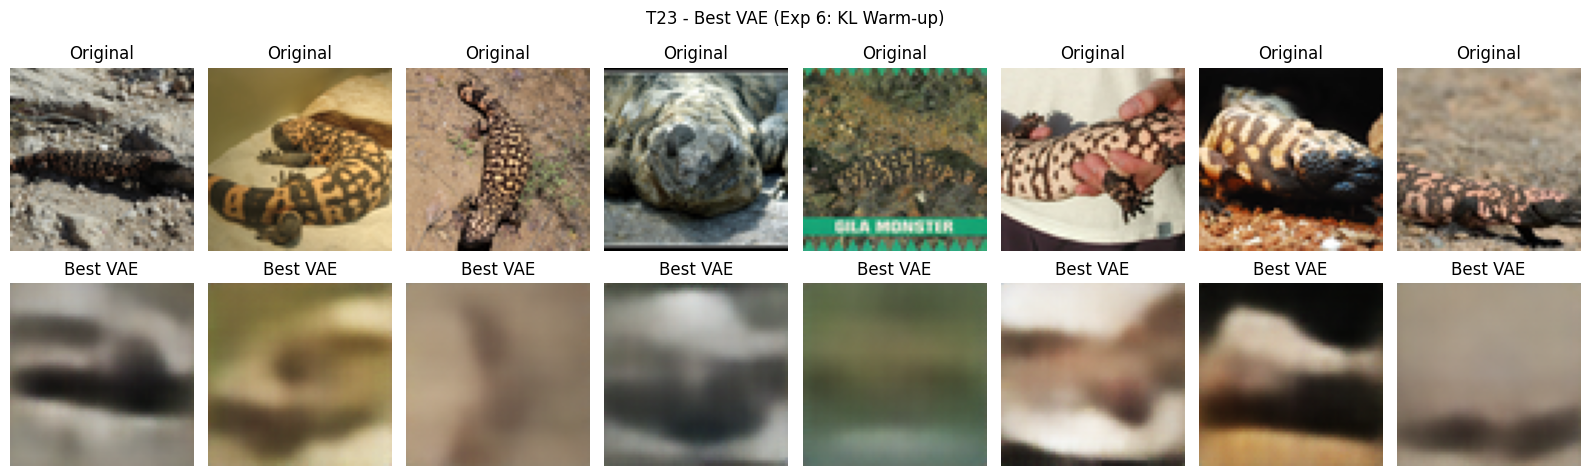

Best VAE reconstruction images saved!


In [48]:

import torch
import matplotlib.pyplot as plt
from pathlib import Path

device = torch.device("cuda:0")

# Load the selected VAE checkpoint
path = Path(
    "/kaggle/working/vae_results/T23_BEST_VAE.pt"
)

checkpoint = torch.load(
    path,
    map_location=device,
    weights_only=False
)

model = VAE(latent_dim=128).to(device)
model.load_state_dict(checkpoint["model"])
model.eval()

# Get 8 validation images
x = next(iter(val_loader))[:8].to(device)

with torch.no_grad():
    mu, logvar = model.encoder(x)
    recon = model.decoder(mu)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):

    original = x[i].cpu().permute(1, 2, 0).numpy()
    reconstructed = (
        recon[i].cpu().permute(1, 2, 0).numpy()
    )

    axes[0, i].imshow(original)
    axes[0, i].axis("off")
    axes[0, i].set_title("Original")

    axes[1, i].imshow(reconstructed)
    axes[1, i].axis("off")
    axes[1, i].set_title("Best VAE")

plt.suptitle("T23 - Best VAE (Exp 6: KL Warm-up)")
plt.tight_layout()

output = Path("/kaggle/working/results")
output.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output / "best_vae_reconstructions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Best VAE reconstruction images saved!")


In [49]:
import pandas as pd
from pathlib import Path

final_table = pd.DataFrame([
    {
        "Experiment": "Exp 1",
        "Description": "Baseline",
        "Latent Dimension": 128,
        "Beta": 1.0,
        "KL Warm-up": "OFF",
        "Best Epoch": 20,
        "Best VAL MSE": 0.017029,
        "Best VAL KL": 60.953118,
        "Best VAL Negative ELBO": 270.211533,
        "Active Units": 125,
        "Training Time (s)": 169.95,
        "Peak GPU Memory (MB)": 141.49
    },
    {
        "Experiment": "Exp 2",
        "Description": "Latent dimension: 128 → 64",
        "Latent Dimension": 64,
        "Beta": 1.0,
        "KL Warm-up": "OFF",
        "Best Epoch": 20,
        "Best VAL MSE": 0.017074,
        "Best VAL KL": 59.639558,
        "Best VAL Negative ELBO": 269.443331,
        "Active Units": 63,
        "Training Time (s)": 91.87,
        "Peak GPU Memory (MB)": None
    },
    {
        "Experiment": "Exp 3",
        "Description": "Latent dimension: 128 → 256",
        "Latent Dimension": 256,
        "Beta": 1.0,
        "KL Warm-up": "OFF",
        "Best Epoch": 18,
        "Best VAL MSE": 0.017401,
        "Best VAL KL": 59.025991,
        "Best VAL Negative ELBO": 272.846067,
        "Active Units": 255,
        "Training Time (s)": 70.48,
        "Peak GPU Memory (MB)": 176.78
    },
    {
        "Experiment": "Exp 4",
        "Description": "Beta: 1 → 0.5",
        "Latent Dimension": 128,
        "Beta": 0.5,
        "KL Warm-up": "OFF",
        "Best Epoch": 19,
        "Best VAL MSE": 0.015006,
        "Best VAL KL": 88.095231,
        "Best VAL Negative ELBO": 272.487074,
        "Active Units": 127,
        "Training Time (s)": 69.00,
        "Peak GPU Memory (MB)": 154.39
    },
    {
        "Experiment": "Exp 5",
        "Description": "Beta: 1 → 2",
        "Latent Dimension": 128,
        "Beta": 2.0,
        "KL Warm-up": "OFF",
        "Best Epoch": 20,
        "Best VAL MSE": 0.020422,
        "Best VAL KL": 36.517177,
        "Best VAL Negative ELBO": 287.466751,
        "Active Units": 127,
        "Training Time (s)": 68.97,
        "Peak GPU Memory (MB)": 154.39
    },
    {
        "Experiment": "Exp 6",
        "Description": "KL Warm-up: OFF → ON",
        "Latent Dimension": 128,
        "Beta": 1.0,
        "KL Warm-up": "ON",
        "Best Epoch": 20,
        "Best VAL MSE": 0.016602,
        "Best VAL KL": 63.514199,
        "Best VAL Negative ELBO": 267.514929,
        "Active Units": 126,
        "Training Time (s)": 69.29,
        "Peak GPU Memory (MB)": 154.39
    }
])

display(final_table)

results_dir = Path("/kaggle/working/results")
results_dir.mkdir(parents=True, exist_ok=True)

final_table.to_csv(results_dir / "final_vae_summary_table.csv", index=False)

print("Final summary table saved!")
print(results_dir / "final_vae_summary_table.csv")

,Experiment,Description,Latent Dimension,Beta,KL Warm-up,Best Epoch,Best VAL MSE,Best VAL KL,Best VAL Negative ELBO,Active Units,Training Time (s),Peak GPU Memory (MB)
0,Exp 1,Baseline,128,1.0,OFF,20,0.017029,60.953118,270.211533,125,169.95,141.49
1,Exp 2,Latent dimension: 128 → 64,64,1.0,OFF,20,0.017074,59.639558,269.443331,63,91.87,NaN
2,Exp 3,Latent dimension: 128 → 256,256,1.0,OFF,18,0.017401,59.025991,272.846067,255,70.48,176.78
3,Exp 4,Beta: 1 → 0.5,128,0.5,OFF,19,0.015006,88.095231,272.487074,127,69.00,154.39
4,Exp 5,Beta: 1 → 2,128,2.0,OFF,20,0.020422,36.517177,287.466751,127,68.97,154.39
5,Exp 6,KL Warm-up: OFF → ON,128,1.0,ON,20,0.016602,63.514199,267.514929,126,69.29,154.39


Final summary table saved!
/kaggle/working/results/final_vae_summary_table.csv
